# 04 — Arquitetura avançada (Transfer Learning) e Grad-CAM

**Data Challenge | Desafio 1: Classificação de doenças em folhas**

Continuação dos notebooks 01–03. Esta etapa tem dois objetivos:

1. **Estudo de arquitetura (Parte A).** Pesquisar e comparar arquiteturas de Transfer Learning (MobileNetV2, EfficientNetB0, ResNet50) e **justificar** qual o grupo levará para a Entrega 2. Nesta entrega (checkpoint) o Transfer Learning **não é treinado** — é um estudo prévio para escolher o modelo certo. O construtor `build_transfer_model` já deixa o pipeline pronto para o treino da Entrega 2.
2. **Grad-CAM (Parte B, bônus).** Aplicar Grad-CAM sobre o baseline **com augmentation** treinado no notebook 03, para verificar a hipótese da EDA (notebook 02, seções 4 e 7): o modelo olha para a folha e as lesões, ou se apoia no fundo (solo, mão, outras folhas)?

## 1. Continuação dos notebooks anteriores

Esta etapa precisa de dois insumos: os **dados** (`dataset`, `labels`, `test_ds`, do pipeline da etapa 1) e o **modelo baseline + augmentation** treinado no notebook 03.

A célula abaixo resolve os dois da forma mais barata possível:

- Se o notebook 03 já rodou **nesta sessão** (variável `runs` disponível), reaproveita tudo — modelos e dados — sem reexecutar nada.
- Senão, executa apenas o **notebook 01** com `%run` (ingestão e pré-processamento, rápido, **sem treino**) para obter os dados, e carrega o modelo salvo `data/processed/baseline_aug.keras` (produzido na seção 9 do notebook 03).
- Só se o modelo salvo não existir é que recorremos a `%run` do 03 (que treina as CNNs do zero, ~20–30 min em CPU).

Assim o notebook roda em segundos quando o 03 já foi executado, e continua funcionando do zero. A verificação vale por sessão do kernel: se alterar um notebook anterior, reinicie o kernel.

In [1]:
from pathlib import Path

from IPython import get_ipython
from IPython.utils.capture import capture_output

notebook_dir = Path.cwd()
if (notebook_dir / 'notebooks').is_dir():
    notebook_dir = notebook_dir / 'notebooks'
project_root = notebook_dir.parent
artifacts_dir = project_root / 'data' / 'processed'
baseline_aug_path = artifacts_dir / 'baseline_aug.keras'

# baseline_aug reaproveitado da sessão, carregado do disco, ou treinado (último caso).
gradcam_model = None

if 'runs' in globals() and 'baseline_aug' in globals().get('runs', {}):
    # (a) Notebook 03 já rodou nesta sessão: reaproveita modelos e dados.
    source = 'sessão (runs do notebook 03)'
    gradcam_model = runs['baseline_aug']['model']
elif baseline_aug_path.is_file():
    # (b) Modelo salvo existe: roda só o 01 (dados, sem treino) e carrega o modelo.
    source = 'data/processed/baseline_aug.keras (+ dados do notebook 01)'
    with capture_output():
        get_ipython().run_line_magic('run', f'"{notebook_dir / "01_data_ingestion_preprocessing.ipynb"}"')
else:
    # (c) Sem modelo salvo: executa o 03 (treina as CNNs do zero).
    source = '%run do notebook 03 (treino completo)'
    with capture_output():
        get_ipython().run_line_magic('run', f'"{notebook_dir / "03_baseline_model.ipynb"}"')
    gradcam_model = runs['baseline_aug']['model']

# Dados necessários à etapa 4 (vêm do 01 em qualquer caminho acima).
required = ['SEED', 'set_global_seed', 'IMAGE_SIZE', 'labels', 'dataset', 'test_ds',
            'pd', 'plt', 'sns', 'np']
missing = [name for name in required if name not in globals()]
assert not missing, f'Variáveis indisponíveis: {missing}. Reinicie o kernel e rode de novo.'

FIGURES_DIR = project_root / 'reports' / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print('fonte do baseline + augmentation:', source)
print('classes:', labels)
print('imagens de teste:', len(dataset['test']))

fonte do baseline + augmentation: data/processed/baseline_aug.keras (+ dados do notebook 01)
classes: ['angular_leaf_spot', 'bean_rust', 'healthy']
imagens de teste: 128


## 2. Setup específico da etapa 4

Importamos os helpers do pacote: `BACKBONES` e `build_transfer_model` (estudo de arquitetura) e as funções de Grad-CAM. Fixamos a semente para a seleção de exemplos ser reprodutível.

In [2]:
from tensorflow import keras

from bean_leaf_disease.models import BACKBONES, build_transfer_model
from bean_leaf_disease.evaluation import (
    find_last_conv_layer,
    make_gradcam_heatmap,
    overlay_heatmap,
)

set_global_seed(SEED, deterministic=True)
print('figuras em:', FIGURES_DIR)

figuras em: /Users/I754143/repos/bean-leaf-disease-challenge/reports/figures


## 3. Parte A — Estudo de arquiteturas de Transfer Learning

O baseline do notebook 03 é uma CNN pequena (23.779 parâmetros) treinada do zero, com cerca de 83% de acurácia no teste. O conjunto de treino tem apenas **1034 imagens**, e a EDA (notebook 02) mostrou que as lesões ocupam uma área pequena da folha e que o fundo (solo, mão) varia muito. Nesse cenário, treinar do zero uma rede grande tende a sofrer overfitting.

**Transfer Learning** contorna isso: usamos um backbone pré-treinado em ImageNet (1,2 milhão de imagens, 1000 classes) como **extrator de características**. As camadas convolucionais já aprenderam bordas, texturas e padrões que se transferem bem para folhas, e só treinamos um classificador leve no topo. É a abordagem padrão para datasets pequenos.

Comparamos três candidatas comuns, todas com entrada 224×224 (a mesma do pipeline da etapa 1).

In [3]:
tabela = pd.DataFrame(BACKBONES).T
tabela = tabela[['params_millions', 'size_mb', 'imagenet_top1', 'expects', 'note']]
tabela = tabela.rename(
    columns={
        'params_millions': 'parâmetros (M)',
        'size_mb': 'tamanho (MB)',
        'imagenet_top1': 'top-1 ImageNet',
        'expects': 'entrada esperada',
        'note': 'leitura para viabilidade',
    }
)
tabela['top-1 ImageNet'] = (tabela['top-1 ImageNet'].astype(float) * 100).round(1).astype(str) + '%'
with pd.option_context('display.max_colwidth', None):
    display(tabela)

,parâmetros (M),tamanho (MB),top-1 ImageNet,entrada esperada,leitura para viabilidade
MobileNetV2,3.5,14,71.3%,"[-1, 1]","Menor footprint. Projetado para dispositivos móveis/embarcados, adequado a inferência em campo. Treino rápido e menor risco de overfitting num dataset pequeno."
EfficientNetB0,5.3,29,77.1%,"[0, 255]","Melhor acurácia ImageNet entre as candidatas, ainda compacto. A normalização é interna ao modelo (espera pixels em [0, 255])."
ResNet50,25.6,98,74.9%,"caffe (BGR, centrado)",Arquitetura robusta e muito usada como referência. Maior e mais custosa; serve de teto de capacidade na comparação.


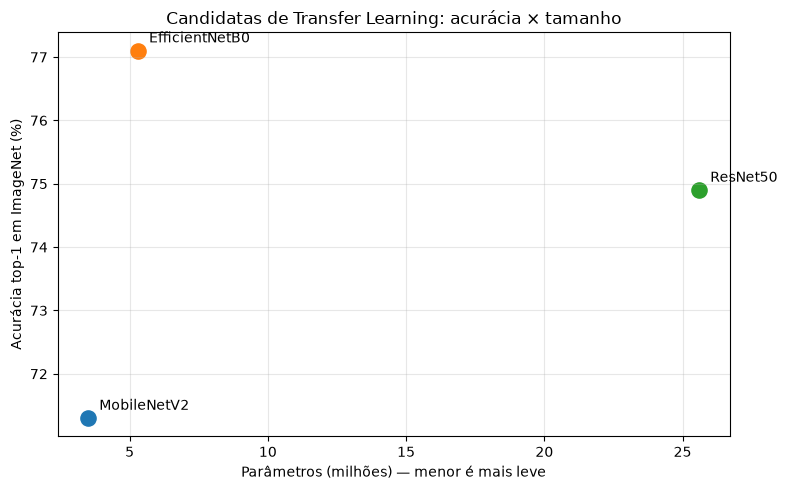

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, spec in BACKBONES.items():
    ax.scatter(spec['params_millions'], spec['imagenet_top1'] * 100, s=120)
    ax.annotate(
        name,
        (spec['params_millions'], spec['imagenet_top1'] * 100),
        textcoords='offset points', xytext=(8, 6),
    )
ax.set_xlabel('Parâmetros (milhões) — menor é mais leve')
ax.set_ylabel('Acurácia top-1 em ImageNet (%)')
ax.set_title('Candidatas de Transfer Learning: acurácia × tamanho')
ax.grid(True, alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'tl_arquiteturas.png', dpi=150, bbox_inches='tight')
plt.show()

### 3.1 Justificativa da escolha

As três candidatas superam com folga o baseline treinado do zero em ImageNet, mas a escolha para a Entrega 2 pesa **acurácia, custo e viabilidade operacional** (deploy em campo ou na agroindústria, tema pedido no enunciado da Entrega 2):

- **MobileNetV2 — escolha recomendada.** Menor footprint (3,5M parâmetros, 14 MB), projetado para dispositivos móveis/embarcados. É o mais adequado a inferência em campo (celular, borda) e o de menor risco de overfitting nas 1034 imagens de treino. Treina rápido, o que facilita iterar na Entrega 2 (feature extraction + fine-tuning).
- **EfficientNetB0 — alternativa de maior acurácia.** Melhor top-1 ImageNet (77,1%) ainda com tamanho moderado (5,3M, 29 MB). Fica como plano B se o MobileNetV2 não separar bem `bean_rust` de `angular_leaf_spot` (a confusão observada no notebook 03). Atenção: sua normalização é interna (espera pixels em [0, 255]).
- **ResNet50 — referência de capacidade.** Robusta e muito usada, mas grande (25,6M, 98 MB) e mais custosa, sem ganho claro de acurácia sobre a EfficientNetB0 aqui. Serve de teto de capacidade na comparação, não de candidata para deploy leve.

**Decisão (a confirmar com os experimentos da Entrega 2):** começar por **MobileNetV2** como extrator de características e, se necessário, liberar o fine-tuning das camadas superiores. A EfficientNetB0 entra como comparação se o ganho justificar o custo.

### 3.2 Pipeline pronto para a Entrega 2 (sem treinar)

`build_transfer_model` monta o modelo escolhido com o **mesmo topo do baseline** (GlobalAveragePooling2D → Dropout(0.3) → Dense softmax), para a comparação baseline × transfer learning ser justa. O pipeline da etapa 1 entrega pixels em [0, 1]; o construtor insere `Rescaling(255.0)` + o `preprocess_input` do backbone, então casa com `make_tf_dataset` sem alterar o pré-processamento.

Construímos o modelo apenas para mostrar a estrutura e a proporção de parâmetros congelados (feature extraction). **Nada é treinado aqui.**

In [5]:
tl_model = build_transfer_model('MobileNetV2', num_classes=len(labels), image_size=IMAGE_SIZE)

trainable = sum(keras.backend.count_params(w) for w in tl_model.trainable_weights)
non_trainable = sum(keras.backend.count_params(w) for w in tl_model.non_trainable_weights)
print(f'Parâmetros treináveis (topo):   {trainable:,}')
print(f'Parâmetros congelados (backbone): {non_trainable:,}')
print(
    'Observe: com o backbone congelado, só o classificador do topo é treinado — '
    'poucos milhares de parâmetros, viável com 1034 imagens.'
)

Parâmetros treináveis (topo):   3,843
Parâmetros congelados (backbone): 2,257,984
Observe: com o backbone congelado, só o classificador do topo é treinado — poucos milhares de parâmetros, viável com 1034 imagens.


## 4. Parte B — Grad-CAM sobre o baseline + augmentation

O Grad-CAM destaca as regiões que mais pesaram na predição de uma classe. Aplicamos sobre o modelo **baseline + augmentation** do notebook 03 (o escolhido lá pela regra de seleção por validação) para responder: **o modelo olha para a folha ou para o fundo?**

Usamos a última camada convolucional do baseline como alvo (mapa de ativação 28×28×64; ver `find_last_conv_layer`).

In [6]:
# No caso (b) — modelo salvo em disco — ainda precisamos carregá-lo aqui.
if gradcam_model is None:
    gradcam_model = keras.models.load_model(baseline_aug_path)

last_conv = find_last_conv_layer(gradcam_model)
print('modelo Grad-CAM pronto | última camada convolucional (alvo):', last_conv)

modelo Grad-CAM pronto | última camada convolucional (alvo): max_pooling2d_8


### 4.1 Seleção de exemplos

Escolhemos exemplos do conjunto de **teste** (não usado no treino): um acerto de cada classe e, para contraste, um **erro** — priorizando a confusão `bean_rust` ↔ `angular_leaf_spot` observada na matriz de confusão do notebook 03. Cada imagem é pré-processada do mesmo jeito que no treino (224×224, pixels em [0, 1]).

In [7]:
import tensorflow as tf

# Reconstrói as imagens de teste na ordem original, pré-processadas (224x224, [0,1]).
test_images = []
test_labels = []
for images, lbls in test_ds:
    test_images.append(images.numpy())
    test_labels.append(lbls.numpy())
test_images = np.concatenate(test_images)
test_labels = np.concatenate(test_labels)

# Predições do baseline_aug sobre o teste.
probs = gradcam_model.predict(test_images, verbose=0)
preds = probs.argmax(axis=1)

# Um acerto por classe + um erro (de preferência bean_rust <-> angular_leaf_spot).
selected = []
for class_id in range(len(labels)):
    hits = np.flatnonzero((test_labels == class_id) & (preds == class_id))
    if len(hits):
        selected.append(('acerto', int(hits[0])))

errors = np.flatnonzero(test_labels != preds)
if len(errors):
    pair = {labels.index('bean_rust'), labels.index('angular_leaf_spot')}
    priority = [i for i in errors if test_labels[i] in pair and preds[i] in pair]
    selected.append(('erro', int(priority[0] if priority else errors[0])))

for tag, idx in selected:
    print(f'{tag}: real={labels[test_labels[idx]]}, previsto={labels[preds[idx]]} (idx {idx})')

acerto: real=angular_leaf_spot, previsto=angular_leaf_spot (idx 0)
acerto: real=bean_rust, previsto=bean_rust (idx 43)
acerto: real=healthy, previsto=healthy (idx 86)
erro: real=angular_leaf_spot, previsto=bean_rust (idx 13)


### 4.2 Mapas de calor

Para cada exemplo: imagem original, mapa de calor sobreposto e o rótulo real/previsto. Vermelho = região que mais pesou na predição.

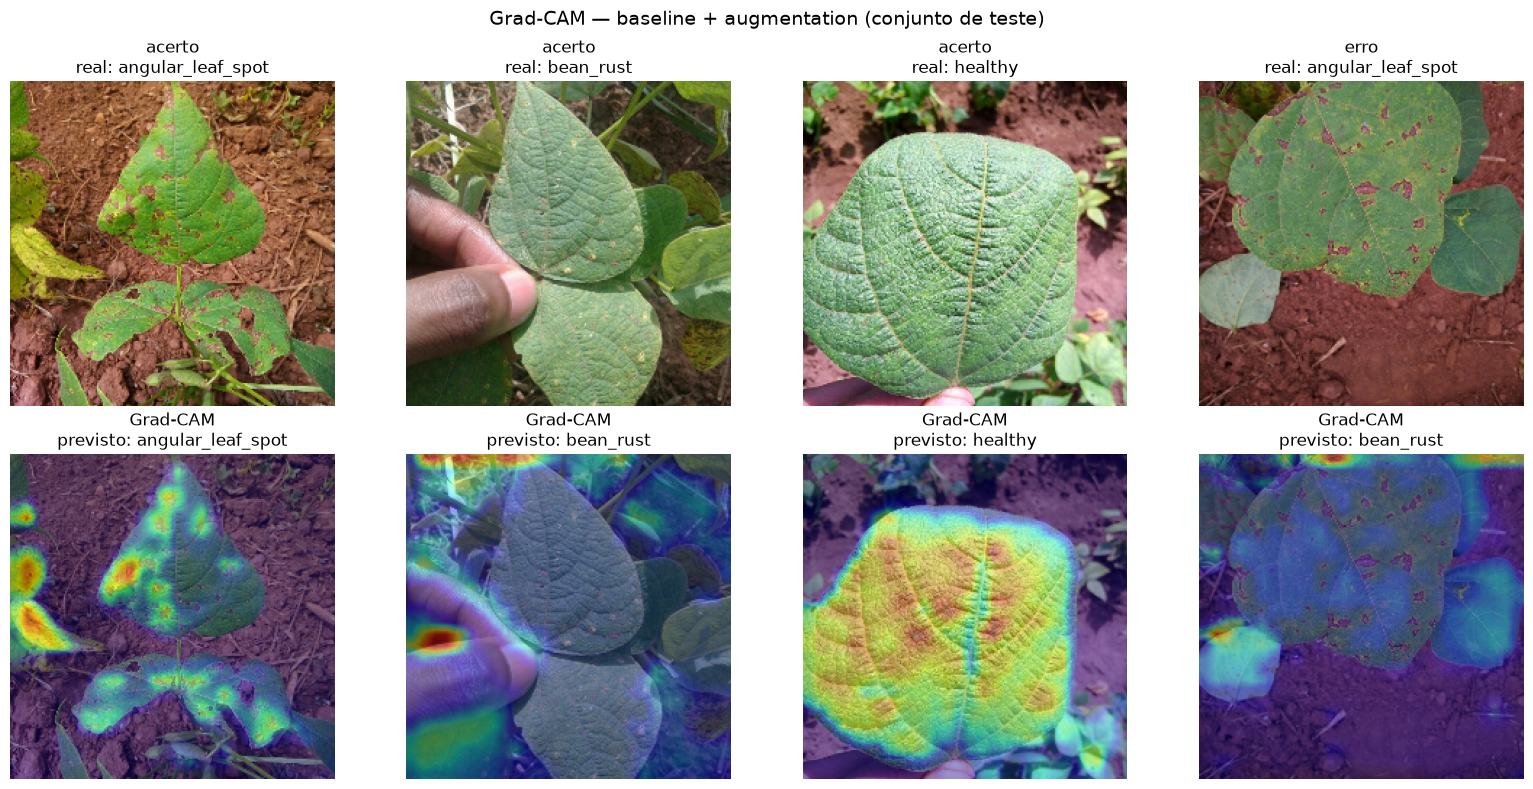

In [8]:
n = len(selected)
fig, axes = plt.subplots(2, n, figsize=(4 * n, 8))
axes = np.atleast_2d(axes)

for col, (tag, idx) in enumerate(selected):
    image = test_images[idx]
    img_batch = image[np.newaxis, ...]
    heatmap = make_gradcam_heatmap(img_batch, gradcam_model, last_conv, pred_index=int(preds[idx]))
    overlaid = overlay_heatmap(image, heatmap)

    real, previsto = labels[test_labels[idx]], labels[preds[idx]]
    axes[0, col].imshow(image)
    axes[0, col].set_title(f'{tag}\nreal: {real}')
    axes[1, col].imshow(overlaid)
    axes[1, col].set_title(f'Grad-CAM\nprevisto: {previsto}')
    for ax in axes[:, col]:
        ax.axis('off')

fig.suptitle('Grad-CAM — baseline + augmentation (conjunto de teste)', fontsize=14)
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'gradcam_baseline.png', dpi=150, bbox_inches='tight')
plt.show()

### 4.3 Leitura dos resultados

O que observar nos mapas de calor (preencher após a execução, pois depende das imagens sorteadas):

- **Foco na folha vs. fundo.** Se o vermelho se concentra na folha e sobre as lesões, o modelo aprendeu o sinal certo. Se pesa sobre solo, mão ou outras folhas, há o atalho de fundo alertado na EDA (notebook 02, seções 4 e 7) — a augmentation (flip, rotação, brilho, contraste) serve justamente para reduzir essa dependência.
- **Caso de erro.** No exemplo mal classificado, ver se o modelo olhou para uma região sem lesão ou confundiu manchas — ajuda a explicar a confusão `bean_rust` ↔ `angular_leaf_spot` do notebook 03.
- **Resolução do mapa.** O mapa vem de uma camada 28×28, então é grosseiro: indica regiões, não lesões individuais. Na Entrega 2, o Grad-CAM sobre o backbone de Transfer Learning (camadas mais profundas e finas) tende a localizar melhor.

> Observação: o baseline tem apenas 3 blocos convolucionais, então o mapa é de baixa resolução. Ele responde à pergunta "folha ou fundo?", mas não substitui a análise mais fina que faremos sobre o modelo final.

## 5. Conclusões e próximos passos (Entrega 2)

**Conclusões desta etapa (checkpoint):**
- Comparamos três arquiteturas de Transfer Learning e justificamos a escolha pela combinação de acurácia, custo e viabilidade de deploy em campo. **Recomendação: MobileNetV2** (menor footprint, menor risco de overfitting no dataset pequeno), com EfficientNetB0 como alternativa de maior acurácia.
- O construtor `build_transfer_model` deixa o pipeline pronto: mesmo topo do baseline, pré-processamento compatível com a etapa 1 e backbone congelado para feature extraction.
- O Grad-CAM sobre o baseline + augmentation permite verificar se o modelo olha para a folha ou para o fundo — insumo direto para a discussão de confiabilidade.

**Próximos passos (Entrega 2):**
1. Treinar o MobileNetV2 em duas fases: feature extraction (backbone congelado) e, depois, fine-tuning das camadas superiores, com o mesmo teto de 200 épocas e paciência 10 do notebook 03.
2. Comparar com o baseline usando as métricas oficiais (acurácia global, F1-macro, matriz de confusão) — reaproveitando os JSONs salvos em `data/processed/`.
3. Rodar o Grad-CAM sobre o modelo de Transfer Learning final (camadas mais profundas, localização mais fina) e discutir a viabilidade operacional no campo/agroindústria.